# Zgodność anotacji - Wykop

Trzy osoby niezależnie oznaczyły te same 150 wpisów z Wykopu etykietami z promptu klasyfikacji (`amc/classification/job_concern.py`):

- `ai` - czy wpis dotyczy sztucznej inteligencji (`yes`/`no`),
- `work` - czy wpis dotyczy pracy, kariery lub rynku pracy (`yes`/`no`),
- `stance` - co autor mówi o wpływie AI na pracę: `threat`, `reassurance`, `opportunity`,
  `mixed`, `none`.

Pytania:

1. Na ile anotatorzy zgadzają się między sobą (czy etykiety są w ogóle dobrze zdefiniowane)?
2. Na ile model (Qwen przez Ollamę) zgadza się z anotatorami i czy mieści się w zakresie zgodności między ludźmi?

Pliki: `data/wykop/Anotacje_Wykop_<imię>.xlsx` (anotatorzy), etykiety modelu z `data/wykop/wykop_classified.csv` (plik `Anotacje_Wykop_todo.xlsx` zawiera te same etykiety modelu, co sprawdzamy niżej).

In [96]:
import sys
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "..")
from amc.classification.job_concern import PROMPT_HASH, STANCE, YES_NO  # noqa: E402

pd.set_option("display.max_colwidth", 200)
plt.rcParams["figure.figsize"] = (10, 4)

DATA = Path("../data/wykop")
OUT = DATA / "agreement"
OUT.mkdir(exist_ok=True)

ANNOTATORS = ["Mikołaj", "Patrycja", "Zuza"]
LABELS = ["ai", "work", "stance"]
CATEGORIES = {"ai": YES_NO, "work": YES_NO, "stance": STANCE}
SEED = 20261025
KEY = ["type", "entry_id"]

## Wczytanie danych

In [97]:
def load_annotations(name):
    df = pd.read_excel(DATA / f"Anotacje_Wykop_{name}.xlsx", sheet_name="sample", dtype=str)
    df = df.dropna(subset=["entry_id"])
    for column in LABELS:
        df[column] = df[column].str.strip().str.lower()
    return df


sheets = {name: load_annotations(name) for name in ANNOTATORS}
base = sheets[ANNOTATORS[0]][[*KEY, "created_at", "url", "text"]].reset_index(drop=True)
for name, df in sheets.items():
    assert df[KEY].reset_index(drop=True).equals(base[KEY]), f"{name}: inne wpisy lub kolejność"
print("wpisów:", len(base), "| anotatorów:", len(sheets))

model_all = pd.read_csv(DATA / "wykop_classified.csv", dtype=str, encoding="utf-8-sig")
model_all = model_all[model_all["prompt_hash"] == PROMPT_HASH]
model = base[KEY].merge(model_all, on=KEY, how="left", validate="one_to_one")
assert model["stance"].notna().all(), "brak etykiet modelu dla części wpisów"
print("model:", model["model"].unique(), "| prompt:", PROMPT_HASH[:8])

todo = load_annotations("todo")
same = (todo[LABELS].reset_index(drop=True) == model[LABELS]).all(axis=1)
print("plik todo = etykiety modelu:", same.sum(), "/", len(same))

wpisów: 150 | anotatorów: 3
model: ['qwen3:8b'] | prompt: 72f3a1da
plik todo = etykiety modelu: 150 / 150


In [98]:
# Jedna tabela: wiersz = wpis, kolumny = etykieta i oceniający
RATERS = [*ANNOTATORS, "model"]
ratings = {"model": model}
ratings.update(sheets)

table = base.copy()
for rater in RATERS:
    df = ratings[rater].reset_index(drop=True)
    for column in LABELS:
        table[(column, rater)] = df[column].values


def labels_of(label, raters=ANNOTATORS):
    return np.column_stack([table[(label, rater)] for rater in raters])


# Wartości spoza słownika i etykiety niespójne z regułą promptu
for rater in RATERS:
    for label in LABELS:
        bad = ~pd.Series(labels_of(label, [rater])[:, 0]).isin(CATEGORIES[label])
        if bad.any():
            print(f"{rater}: {bad.sum()} niepoprawnych wartości w {label}")
    rule = (
        (table[("stance", rater)] != "none")
        & ((table[("ai", rater)] == "no") | (table[("work", rater)] == "no"))
    )
    print(f"{rater:9} stance bez ai=yes i work=yes: {rule.sum()}")

Mikołaj   stance bez ai=yes i work=yes: 0
Patrycja  stance bez ai=yes i work=yes: 0
Zuza      stance bez ai=yes i work=yes: 0
model     stance bez ai=yes i work=yes: 0


## Rozkład etykiet

Duża przewaga jednej kategorii (np. `stance = none`) obniża kappę nawet przy wysokiej zgodności procentowej (paradoks kappy), dlatego obok kapp podajemy też procent zgodności.

In [99]:
distribution = pd.concat(
    {
        label: pd.DataFrame(
            {rater: table[(label, rater)].value_counts() for rater in RATERS}
        ).reindex(CATEGORIES[label]).fillna(0).astype(int)
        for label in LABELS
    }
)
distribution

Mikołaj  Patrycja  Zuza  model
ai     yes               64        68    61     83
       no                86        82    89     67
work   yes               95       103    94    119
       no                55        47    56     31
stance threat            17        16    16     51
       reassurance        3         4     2      2
       opportunity        9         8     7      8
       mixed              0         1     0      0
       none             121       121   125     89

## Miary zgodności

Trzy miary dla danych nominalnych, wyliczone wprost ze wzorów:

- **zgodność procentowa** - odsetek par ocen, które są takie same;
- **kappa Cohena** - dla pary oceniających (także model z człowiekiem), z poprawką na zgodność przypadkową wynikającą z rozkładu etykiet każdego z nich;
- **kappa Fleissa** - jedna liczba dla całej trójki anotatorów.

Przedziały ufności 95% z bootstrapu po wpisach (2000 losowań). Opis słowny kapp według Landisa i Kocha (1977).

In [100]:
def category_counts(values, categories):
    """Macierz wpis x kategoria: ilu oceniających wybrało daną kategorię."""
    return np.stack([(values == c).sum(axis=1) for c in categories], axis=1)


def percent_agreement(values):
    """Odsetek zgodnych par ocen; dla dwóch oceniających to odsetek identycznych ocen."""
    n = category_counts(values, np.unique(values))
    m = values.shape[1]
    return (((n**2).sum(axis=1) - m) / (m * (m - 1))).mean()


def cohen_kappa(values):
    a, b = values[:, 0], values[:, 1]
    p_o = np.mean(a == b)
    p_e = sum(np.mean(a == c) * np.mean(b == c) for c in np.union1d(a, b))
    return (p_o - p_e) / (1 - p_e) if p_e < 1 else np.nan


def fleiss_kappa(values):
    n = category_counts(values, np.unique(values))
    p_e = ((n.sum(axis=0) / n.sum()) ** 2).sum()
    p_o = percent_agreement(values)
    return (p_o - p_e) / (1 - p_e) if p_e < 1 else np.nan


def bootstrap(statistic, values, iterations=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    draws = [
        statistic(values[rng.integers(0, len(values), len(values))])
        for _ in range(iterations)
    ]
    return np.nanpercentile(draws, [2.5, 97.5])


def landis_koch(value):
    """Opis słowny według Landisa i Kocha (1977)."""
    if np.isnan(value):
        return ""
    for limit, name in [(0, "brak"), (0.2, "niewielka"), (0.4, "dostateczna"),
                        (0.6, "umiarkowana"), (0.8, "znaczna")]:
        if value <= limit:
            return name
    return "prawie pełna"

In [101]:
# Kontrola wzorów: pełna zgodność daje 1, a oceny losowe i niezależne około 0
check = np.array([["yes", "yes"], ["no", "no"], ["yes", "yes"], ["no", "no"]])
assert np.isclose(cohen_kappa(check), 1) and np.isclose(fleiss_kappa(check), 1)
rng = np.random.default_rng(1)
noise = rng.choice(["yes", "no"], size=(20000, 2))
assert abs(cohen_kappa(noise)) < 0.03 and abs(fleiss_kappa(noise)) < 0.03
assert np.isclose(percent_agreement(check), 1)

## 1. Zgodność między anotatorami

In [102]:
def agreement_table(raters):
    rows = []
    for label in LABELS:
        values = labels_of(label, raters)
        low, high = bootstrap(fleiss_kappa, values)
        rows.append({
            "etykieta": label,
            "zgodność %": percent_agreement(values),
            "kappa Fleissa": fleiss_kappa(values),
            "95% CI": f"[{low:.2f}, {high:.2f}]",
            "ocena": landis_koch(fleiss_kappa(values)),
        })
    return pd.DataFrame(rows).set_index("etykieta")


humans = agreement_table(ANNOTATORS)
humans.to_csv(OUT / "agreement_annotators.csv", encoding="utf-8-sig")
humans.round(3)

,zgodność %,kappa Fleissa,95% CI,ocena
etykieta,,,,
ai,0.942,0.882,"[0.81, 0.94]",prawie pełna
work,0.898,0.776,"[0.69, 0.86]",znaczna
stance,0.909,0.715,"[0.60, 0.82]",znaczna


In [103]:
# Kappa Cohena dla każdej pary oceniających (model też jako oceniający)
pairs = []
for label in LABELS:
    for a, b in combinations(RATERS, 2):
        values = labels_of(label, [a, b])
        low, high = bootstrap(cohen_kappa, values)
        pairs.append({
            "etykieta": label,
            "para": f"{a} - {b}",
            "z modelem": "model" in (a, b),
            "zgodność %": np.mean(values[:, 0] == values[:, 1]),
            "kappa Cohena": cohen_kappa(values),
            "95% CI": f"[{low:.2f}, {high:.2f}]",
        })
pairs = pd.DataFrame(pairs)
pairs.to_csv(OUT / "cohen_pairs.csv", index=False, encoding="utf-8-sig")
pairs.pivot(index="para", columns="etykieta", values="kappa Cohena").round(3)

etykieta,ai,stance,work
para,,,
Mikołaj - Patrycja,0.838,0.660,0.674
Mikołaj - Zuza,0.959,0.829,0.957
Mikołaj - model,0.593,0.402,0.431
Patrycja - Zuza,0.851,0.660,0.691
Patrycja - model,0.644,0.419,0.659
Zuza - model,0.582,0.400,0.452


## 2. Model a anotatorzy

Dwa porównania:

- **model vs każdy anotator** (kappa Cohena) zestawione z kappami par ludzi - jeśli model zgadza się z ludźmi tak jak ludzie między sobą, mieści się w ich zakresie;
- **model vs etykieta złota**, czyli głos większości trojga anotatorów. Przy `stance` remis (trzy różne odpowiedzi) zdarza się rzadko; takie wpisy pomijamy w tym porównaniu.

In [104]:
summary = (
    pairs.assign(kto=np.where(pairs["z modelem"], "model - człowiek", "człowiek - człowiek"))
    .groupby(["etykieta", "kto"])["kappa Cohena"]
    .agg(["mean", "min", "max"])
    .unstack("kto")
)
summary.round(3)

mean                                  min  \
kto      człowiek - człowiek model - człowiek człowiek - człowiek   
etykieta                                                            
ai                     0.882            0.606               0.838   
stance                 0.716            0.407               0.660   
work                   0.774            0.514               0.674   

                                          max                   
kto      model - człowiek człowiek - człowiek model - człowiek  
etykieta                                                        
ai                  0.582               0.959            0.644  
stance              0.400               0.829            0.419  
work                0.431               0.957            0.659

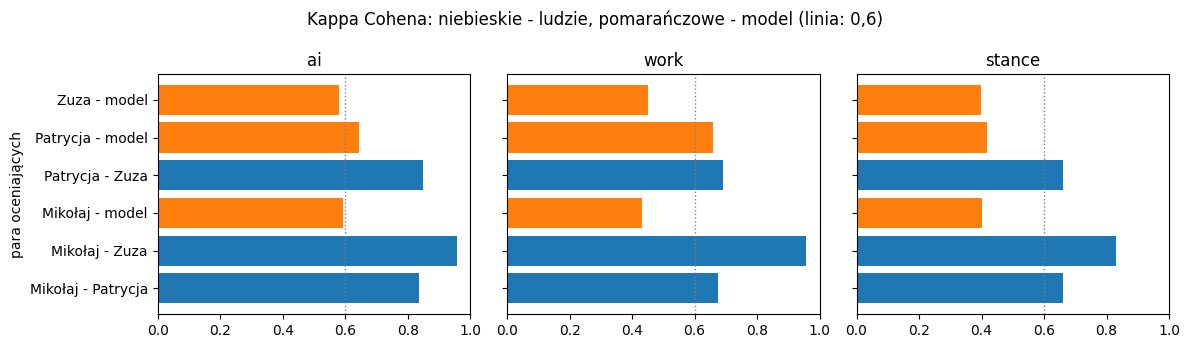

In [105]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, label in zip(axes, LABELS):
    part = pairs[pairs["etykieta"] == label]
    colors = np.where(part["z modelem"], "tab:orange", "tab:blue")
    ax.barh(part["para"], part["kappa Cohena"], color=colors)
    ax.axvline(0.6, color="grey", ls=":", lw=1)
    ax.set_title(label)
    ax.set_xlim(min(0, part["kappa Cohena"].min() - 0.05), 1)
axes[0].set_ylabel("para oceniających")
fig.suptitle("Kappa Cohena: niebieskie - ludzie, pomarańczowe - model (linia: 0,6)")
plt.tight_layout()
plt.savefig(OUT / "cohen_pairs.png", dpi=120)
plt.show()

In [106]:
def majority(values):
    """Głos większości w wierszu; None przy remisie."""
    result = []
    for row in values:
        labels, counts = np.unique(row, return_counts=True)
        top = counts.max()
        result.append(labels[counts.argmax()] if (counts == top).sum() == 1 else None)
    return np.array(result, dtype=object)


for label in LABELS:
    table[(label, "gold")] = majority(labels_of(label))
    votes = labels_of(label)
    table[(label, "jednomyślnie")] = (votes == votes[:, [0]]).all(axis=1)

print("remisy w stance:", table[("stance", "gold")].isna().sum())
print("jednomyślne oceny:", {
    label: int(table[(label, "jednomyślnie")].sum()) for label in LABELS
})

remisy w stance: 1
jednomyślne oceny: {'ai': 137, 'work': 127, 'stance': 130}


In [107]:
def per_class(truth, predicted, categories):
    rows = []
    for c in categories:
        tp = np.sum((predicted == c) & (truth == c))
        fp = np.sum((predicted == c) & (truth != c))
        fn = np.sum((predicted != c) & (truth == c))
        precision = tp / (tp + fp) if tp + fp else np.nan
        recall = tp / (tp + fn) if tp + fn else np.nan
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else np.nan
        rows.append({"kategoria": c, "złota": tp + fn, "model": tp + fp,
                     "precyzja": precision, "czułość": recall, "F1": f1})
    return pd.DataFrame(rows).set_index("kategoria")


vs_gold = []
for label in LABELS:
    keep = table[(label, "gold")].notna().to_numpy()
    values = np.column_stack([table[(label, "gold")], table[(label, "model")]])[keep]
    low, high = bootstrap(cohen_kappa, values)
    vs_gold.append({
        "etykieta": label,
        "wpisów": int(keep.sum()),
        "trafność": np.mean(values[:, 0] == values[:, 1]),
        "kappa Cohena": cohen_kappa(values),
        "95% CI": f"[{low:.2f}, {high:.2f}]",
        "ocena": landis_koch(cohen_kappa(values)),
        "kappa ludzi (średnia par)": summary.loc[label, ("mean", "człowiek - człowiek")],
    })
vs_gold = pd.DataFrame(vs_gold).set_index("etykieta")
vs_gold.to_csv(OUT / "model_vs_gold.csv", encoding="utf-8-sig")
vs_gold.round(3)

,wpisów,trafność,kappa Cohena,95% CI,ocena,kappa ludzi (średnia par)
etykieta,,,,,,
ai,150,0.793,0.594,"[0.47, 0.71]",umiarkowana,0.882
work,150,0.773,0.463,"[0.31, 0.61]",umiarkowana,0.774
stance,149,0.732,0.428,"[0.30, 0.55]",umiarkowana,0.716


In [108]:
# Czy dołączenie modelu jako czwartego oceniającego psuje zgodność grupy?
compare = pd.DataFrame({
    "Fleiss: 3 anotatorów": humans["kappa Fleissa"],
    "Fleiss: 3 anotatorów + model": agreement_table(RATERS)["kappa Fleissa"],
})
compare.round(3)

,Fleiss: 3 anotatorów,Fleiss: 3 anotatorów + model
etykieta,,
ai,0.882,0.741
work,0.776,0.647
stance,0.715,0.523


### Macierze pomyłek i miary per kategoria (model vs złota)

In [109]:
for label in LABELS:
    keep = table[(label, "gold")].notna()
    truth = table[(label, "gold")][keep].astype(str).to_numpy()
    predicted = table[(label, "model")][keep].to_numpy()
    print(f"\n=== {label} (wiersze: złota, kolumny: model)")
    display(pd.crosstab(
        pd.Categorical(truth, CATEGORIES[label]), pd.Categorical(predicted, CATEGORIES[label]),
        rownames=["złota"], colnames=["model"], dropna=False,
    ))
    scores = per_class(truth, predicted, CATEGORIES[label])
    scores.to_csv(OUT / f"per_class_{label}.csv", encoding="utf-8-sig")
    display(scores.round(3))


=== ai (wiersze: złota, kolumny: model)


model,yes,no
złota,,
yes,57,5
no,26,62


,złota,model,precyzja,czułość,F1
kategoria,,,,,
yes,62,83,0.687,0.919,0.786
no,88,67,0.925,0.705,0.800



=== work (wiersze: złota, kolumny: model)


model,yes,no
złota,,
yes,90,5
no,29,26


,złota,model,precyzja,czułość,F1
kategoria,,,,,
yes,95,119,0.756,0.947,0.841
no,55,31,0.839,0.473,0.605



=== stance (wiersze: złota, kolumny: model)


model,threat,reassurance,opportunity,mixed,none
złota,,,,,
threat,16,0,0,0,1
reassurance,1,1,0,0,0
opportunity,1,1,5,0,1
mixed,0,0,0,0,0
none,32,0,3,0,87


,złota,model,precyzja,czułość,F1
kategoria,,,,,
threat,17,50,0.320,0.941,0.478
reassurance,2,2,0.500,0.500,0.500
opportunity,8,8,0.625,0.625,0.625
mixed,0,0,NaN,NaN,NaN
none,122,89,0.978,0.713,0.825


## 3. Próba a cały zbiór

Jeśli próba do anotacji była losowana warstwowo (np. z nadreprezentacją wpisów, które model
oznaczył jako `threat`), trafność i czułość z próby nie przenoszą się wprost na cały zbiór.
Poniżej rozkład etykiet modelu w próbie i we wszystkich sklasyfikowanych wpisach.

In [110]:
population = pd.DataFrame({
    "próba": table[("stance", "model")].value_counts(normalize=True),
    "cały zbiór": model_all["stance"].value_counts(normalize=True),
}).reindex(STANCE).fillna(0)
population.round(3)

,próba,cały zbiór
threat,0.340,0.031
reassurance,0.013,0.000
opportunity,0.053,0.005
mixed,0.000,0.001
none,0.593,0.962


## 4. Rozbieżności do omówienia

Wpisy, w których `stance` modelu różni się od większości anotatorów, oraz wpisy, przy
których anotatorzy się różnili. Te listy są podstawą do doprecyzowania instrukcji anotacji
i promptu. Zapisujemy je do `data/wykop/agreement/`.

In [111]:
def show(mask, label="stance"):
    view = pd.DataFrame({
        "url": table["url"],
        "text": table["text"].str.replace("\n", " ").str.slice(0, 300),
        **{name: table[(label, rater)] for name, rater in
           [*zip(ANNOTATORS, ANNOTATORS), ("złota", "gold"), ("model", "model")]},
    })
    return view[mask.to_numpy()]


model_split = table[("stance", "gold")].notna() & (
    table[("stance", "model")] != table[("stance", "gold")]
)
human_split = ~table[("stance", "jednomyślnie")]
print("model inaczej niż większość:", model_split.sum(),
      "| anotatorzy niezgodni:", human_split.sum())

show(model_split).to_csv(OUT / "model_vs_gold_stance.csv", encoding="utf-8-sig")
show(human_split).to_csv(OUT / "annotators_split_stance.csv", encoding="utf-8-sig")
show(model_split)

model inaczej niż większość: 40 | anotatorzy niezgodni: 20


,url,text,Mikołaj,Patrycja,Zuza,złota,model
2,https://wykop.pl/wpis/71287435/chatgpt-nie-zabierze-ci-pracy-jesli-odpowiednio-go,"ChatGPT nie zabierze Ci pracy, jeśli odpowiednio go wytresujesz xd #openai #chatgpt #programowanie #heheszki",opportunity,opportunity,opportunity,opportunity,reassurance
4,https://wykop.pl/wpis/58542797/dzisiaj-kolejny-dzien-jebania-w-kontraktorni-posre,Dzisiaj kolejny dzień j-----a w kontraktorni/pośredniaku na projekt który z góry miał datę dostarczenia jak jeszcze nie było programistów. Macie z---------ć by dowieźć i elo. #przegryw #korposw...,none,none,none,none,threat
6,https://wykop.pl/wpis/72771881/uznalbym-to-za-anomalie-gdybym-rano-nie-mogl-na-pr,"Uznałbym to za anomalię, gdybym rano nie mógł na pracowych tagach poczytać o tym, jakie to IT złe, a próba wejścia do branży skazana na niepowodzenie i zostanie menelem ( ͡° ͜ʖ ͡°) No to siadamy, ...",none,none,none,none,threat
7,https://wykop.pl/wpis/66489879/klepie-kod-w-skandynawskiej-firmie-lajtowa-robota-,"Klepie kod w skandynawskiej firmie lajtowa robota w sumie na 5 dni przepracuje może 2... nikt nie weryfikuje mojej pracy dosłownie mogę sobie wpisać, że pracowałem 8h nad taskiem który nie istniej...",none,none,none,none,threat
9,https://wykop.pl/wpis/85835727/dystopia-tv-reklama-ai-sztucznainteligencja-co-3-c,#dystopia #tv #reklama #ai #sztucznainteligencja Co 3 cia reklama jest już zrobiona przez AI. Co za parszywy koszmar.,none,none,none,none,threat
11,https://wykop.pl/wpis/87215353/market-mover-dnia-polprzewodniki-wolfspeed-wolf-dz,🚀 **Market Mover Dnia [Półprzewodniki]: Wolfspeed (WOLF)** Dzisiejszy ruch: **+12.19%** Wolfspeed +12.19% dzisiaj. Co się stało? Ruch wynika z najnowszych informacji o partnerstwie z LITEON w za...,none,none,none,none,opportunity
33,https://wykop.pl/wpis/80166599/gdybyscie-mieli-dzisiaj-wybrac-sciezke-kariery-to-,"Gdybyście mieli dzisiaj wybrać ścieżkę kariery, to co byście wybrali? #pracbaza #pracait #studbaza",none,none,none,none,opportunity
36,https://wykop.pl/wpis/81570767/chatgpt-nie-chce-mi-powiedziec-co-mam-zrobic-z-pla,"#chatgpt nie chce mi powiedzieć co mam zrobić z plaga myszy i sugeruje wezwanie fachowca który pewnie weźmie z 200zł, dobrze że są alternatywy",none,none,none,none,threat
41,https://wykop.pl/wpis/76604525/to-tylko-gosc-jedzacy-makaron-jednakze-filmik-zost,To tylko gość jedzący makaron. Jednakże filmik został stworzony wyłącznie przez sztuczną inteligencję. To jest coś niesamowitego i przerażającego jednocześnie. Pewnie za 40 lat będą mieli z nas be...,none,none,none,none,threat
43,https://wykop.pl/wpis/81240517/ai-chatgpt-wg-mnie-to-gowno-z-jednego-powodu-bo-ws,"#ai #chatgpt wg mnie to g---o, z jednego powodu - bo wszystko co mówi to jak dobrze zadasz pytanie to git. Mam premium i coś tam w różnych tematach mi pomaga, ale rozmowa przez pare dni tak spowal...",none,none,none,none,threat


In [112]:
show(human_split)

,url,text,Mikołaj,Patrycja,Zuza,złota,model
5,https://wykop.pl/wpis/79344903/programowanie-programista15k-programista25k-pracba,"#programowanie #programista15k #programista25k #pracbaza #java #pracait #kryzysit #korposwiat A i jeszcze jedno odnośnie kwestia pasjonatów. Pasjonaci tak p------ą, że IT to taka rozwojowa branża...",threat,threat,none,threat,threat
16,https://wykop.pl/wpis/82789411/czyli-mamy-byc-januszami-ai-biznesu-i-aireczki-trz,Czyli mamy być Januszami AI biznesu i AIreczki trzeba kruciutko pod butem i batem. Ehhh czyli wkraczamy w erę leniwych systemów ktore trzeba pilnować i dopraszac sie #ai #sztucznainteligencja #he...,threat,none,threat,threat,threat
17,https://wykop.pl/wpis/69380449/chatgpt-openai-wojsko-no-i-co-mirki-myslicie-ze-mi,"#chatgpt #openai #wojsko No i co mirki, myślicie, że minister się przychili do kobiecej prośby? Swoją drogą zabawne, że mi ten list wygenerował jako kobieta. Jak sprawdzałem inne rzeczy, to pi...",opportunity,none,none,none,none
21,https://wykop.pl/wpis/77288965/programista15k-jak-niby-rozpoznaje-sie-seniora-w-c,#programista15k jak niby rozpoznaje się seniora w cv? W umowie nie mam żadnego stopniowania a byłem nawet managerem projektu bez zmiany umowy. Stopniowanie jest bez sensu jak i zadania rekrutacyjn...,threat,none,threat,threat,threat
39,https://wykop.pl/wpis/82079563/odkryj-jak-stworzyc-wlasny-kanal-youtube-przy-uzyc,"Odkryj, jak stworzyć własny kanał YouTube przy użyciu darmowych narzędzi AI! W tym poradniku pokażę Ci krok po kroku, jak generować scenariusze, głos, wideo i montować profesjonalne filmy bez wyda...",opportunity,none,opportunity,opportunity,opportunity
46,https://wykop.pl/wpis/84323335/to-przez-to-juniorzy-nie-maja-pracy-programowanie-,To przez to juniorzy nie mają pracy? #programowanie #ai,none,threat,none,none,threat
59,https://wykop.pl/wpis/79942375/warto-isc-na-radiologia-jeszcze-skoro-deep-sobie-t,Warto iść na radiologia jeszcze skoro deep sobie tak dobrze radzi? #pytanie #sztucznainteligencja,none,threat,none,none,threat
65,https://wykop.pl/wpis/76738685/nie-wiem-czy-ktos-tu-sledzi-relacje-na-zywo-na-str,"Nie wiem czy ktoś tu śledzi relacje na żywo na stronie https://wyniki.sport.pl/pilka-nozna/Euro-50/Wegry-Szwajcaria-4043838#s=wghp ja czasem to robiłem, szczególnie w pracy, ale to jest teraz taki...",threat,mixed,threat,threat,threat
69,https://wykop.pl/wpis/85595277/poki-co-jesli-chodzi-o-webdev-i-tworzenie-strony-p,"Póki co jeśli chodzi o #webdev i tworzenie strony przez laika, który musi się uczyć wszystkiego to #chatgpt wygrywa nad #claude. Mam za sobą rozgrzewkę dość solidną nad jedną stroną firmową a tera...",none,opportunity,opportunity,opportunity,opportunity
77,https://wykop.pl/wpis/71304783/korzystam-sobie-z-darmowego-chatu-gpt-wersja-3-5-w,"korzystam sobie z darmowego chatu gpt, wersja 3,5. wkręciłem sie cholernie. tylko dzisiaj ogarnął mi zajebiste opisy seo, opisy produktów, wymyślił kampanie reklamową i zredagował teksty. ciekawe ...",none,opportunity,none,none,opportunity
